# NOTEBOOK 04: TẦNG 1 — SO SÁNH MÔ HÌNH NÂNG CAO, TINH CHỈNH NGƯỠNG & ĐÁNH GIÁ TẬP TEST
## HỆ THỐNG HỖ TRỢ HỌC TẬP LỚP 12 VIỆT NAM (CLASSIFICATION PIPELINE)

**Dự án:** Hệ thống Hỗ trợ Học tập Lớp 12  
**Mục tiêu Epic 3 (Phần nâng cao):**
1. **So sánh 3 thuật toán phân loại:**
   - Logistic Regression (+ SMOTE)
   - Random Forest Classifier (+ SMOTE)
   - XGBoost Classifier (+ SMOTE)
2. **Kỷ luật dữ liệu nghiêm ngặt:** Toàn bộ quá trình chọn mô hình và tinh chỉnh ngưỡng quyết định ($T^*$) chỉ được thực hiện trên **Dev Blackbox** (693 học sinh).
3. **Phân tích lỗi định tính (Error Analysis):** Sử dụng tập **Dev Eyeball** (298 học sinh) để phân tích chân dung các ca Báo động giả (False Positive) và Bỏ sót nguy cơ (False Negative).
4. **Đánh giá duy nhất trên tập Test (Hold-out Test 15%):** Mở niêm phong tập Test (992 học sinh) để đo lường năng lực tổng quát hóa thực tế.
5. **Xuất mô hình:** Lưu `models/pipeline_stage1.pkl` và cập nhật siêu dữ liệu `models/model_metadata.json`.

---
## 📦 EPIC 3: MÔ HÌNH NÂNG CAO & TINH CHỈNH TẦNG 1
### 🔹 Task 3.2: So sánh 3 Mô hình Phân loại trên Dev Blackbox & Chọn Mô hình Tối ưu

In [1]:
# CELL 1: Import thư viện và thiết lập môi trường
import os
import json
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score, recall_score, precision_score
)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
SPLITS_DIR = os.path.join(PROJECT_ROOT, 'data', 'splits')
MODELS_DIR = os.path.join(PROJECT_ROOT, 'models')
FIGURES_DIR = os.path.join(PROJECT_ROOT, 'reports', 'figures')
LOGS_DIR = os.path.join(PROJECT_ROOT, 'reports', 'error_logs')

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(LOGS_DIR, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 150
print(f"✅ Đã cấu hình thư mục thành công. PROJECT_ROOT: {PROJECT_ROOT}")

✅ Đã cấu hình thư mục thành công. PROJECT_ROOT: d:\What-If Simulator


In [2]:
# CELL 2: Nạp các tập Train, Dev Blackbox, Dev Eyeball và Test (Chống Leakage)
train_df = pd.read_csv(os.path.join(SPLITS_DIR, 'train.csv'))
dev_bb_df = pd.read_csv(os.path.join(SPLITS_DIR, 'dev_blackbox.csv'))
dev_eye_df = pd.read_csv(os.path.join(SPLITS_DIR, 'dev_eyeball.csv'))
test_df = pd.read_csv(os.path.join(SPLITS_DIR, 'test.csv'))

TARGET = 'at_risk'
LEAKAGE_COL = 'Exam_Score'

X_train = train_df.drop(columns=[TARGET, LEAKAGE_COL])
y_train = train_df[TARGET]

X_dev_bb = dev_bb_df.drop(columns=[TARGET, LEAKAGE_COL])
y_dev_bb = dev_bb_df[TARGET]

X_dev_eye = dev_eye_df.drop(columns=[TARGET, LEAKAGE_COL])
y_dev_eye = dev_eye_df[TARGET]

X_test = test_df.drop(columns=[TARGET, LEAKAGE_COL])
y_test = test_df[TARGET]

print(f"✅ Đã nạp dữ liệu: Train={len(X_train):,}, Dev_BB={len(X_dev_bb):,}, Dev_Eye={len(X_dev_eye):,}, Test={len(X_test):,}")

✅ Đã nạp dữ liệu: Train=4,624, Dev_BB=693, Dev_Eye=298, Test=992


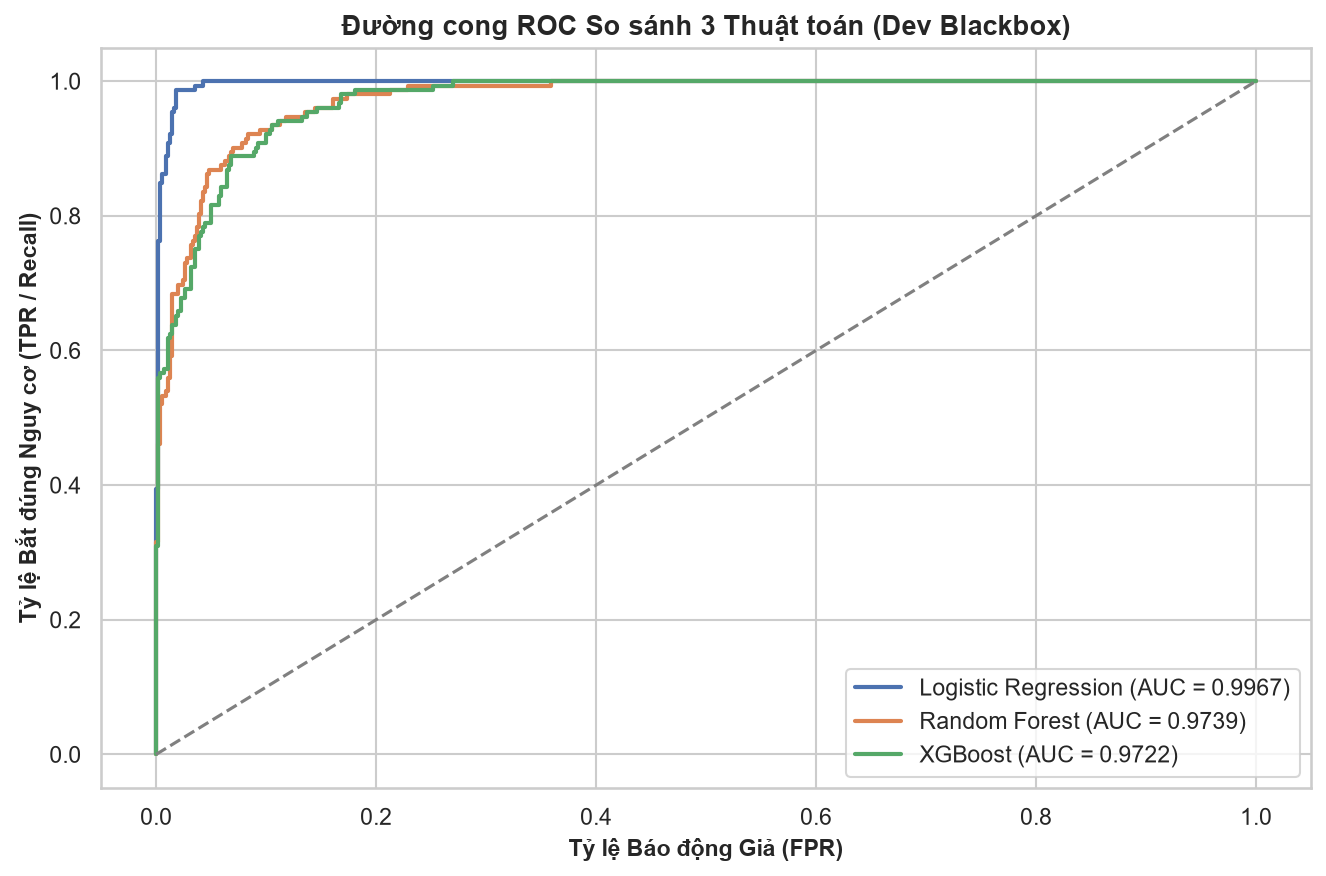

💾 Đã lưu Biểu đồ 7: d:\What-If Simulator\reports\figures\fig7_model_comparison_roc.png

📊 BẢNG SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN TRÊN DEV BLACKBOX:
              Model   Recall  Precision  F1-Score  ROC-AUC
Logistic Regression 0.986842   0.909091  0.946372 0.996704
      Random Forest 0.875000   0.801205  0.836478 0.973940
            XGBoost 0.875000   0.786982  0.828660 0.972201

🏆 Mô hình chiến thắng được chọn: Logistic Regression (F1 = 0.9464, Recall = 0.9868)


In [3]:
# CELL 3: Xây dựng ColumnTransformer và Huấn luyện So sánh 3 Thuật toán trên Dev Blackbox
num_cols = [
    'Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
    'Tutoring_Sessions', 'Physical_Activity', 'effective_study_index'
]
ord_cols = [
    'Parental_Involvement', 'Access_to_Resources', 'Motivation_Level',
    'Family_Income', 'Teacher_Quality', 'Parental_Education_Level'
]
ord_cats = [
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['Low', 'Medium', 'High'],
    ['High School', 'College', 'Postgraduate']
]
nom_cols = [
    'Extracurricular_Activities', 'Internet_Access',
    'Peer_Influence', 'Learning_Disabilities', 'Distance_from_Home'
]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('ord', OrdinalEncoder(categories=ord_cats), ord_cols),
    ('nom', OneHotEncoder(drop='first', sparse_output=False), nom_cols)
])

candidate_models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, C=1.0),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42, eval_metric='logloss')
}

results = []
pipelines = {}

plt.figure(figsize=(9, 6))

for name, clf in candidate_models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('clf', clf)
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    
    y_pred = pipe.predict(X_dev_bb)
    y_prob = pipe.predict_proba(X_dev_bb)[:, 1]
    
    auc = roc_auc_score(y_dev_bb, y_prob)
    rec = recall_score(y_dev_bb, y_pred)
    prec = precision_score(y_dev_bb, y_pred)
    f1 = f1_score(y_dev_bb, y_pred)
    
    results.append({
        'Model': name,
        'Recall': rec,
        'Precision': prec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })
    
    fpr, tpr, _ = roc_curve(y_dev_bb, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5)
plt.title("Đường cong ROC So sánh 3 Thuật toán (Dev Blackbox)", fontsize=13, weight='bold')
plt.xlabel("Tỷ lệ Báo động Giả (FPR)", fontsize=11, weight='bold')
plt.ylabel("Tỷ lệ Bắt đúng Nguy cơ (TPR / Recall)", fontsize=11, weight='bold')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()

fig7_path = os.path.join(FIGURES_DIR, 'fig7_model_comparison_roc.png')
plt.savefig(fig7_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 7: {fig7_path}")

df_results = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
print("\n" + "="*70)
print("📊 BẢNG SO SÁNH HIỆU NĂNG CÁC THUẬT TOÁN TRÊN DEV BLACKBOX:")
print(df_results.to_string(index=False))
print("="*70)

best_model_name = df_results.iloc[0]['Model']
best_pipeline = pipelines[best_model_name]
print(f"\n🏆 Mô hình chiến thắng được chọn: {best_model_name} (F1 = {df_results.iloc[0]['F1-Score']:.4f}, Recall = {df_results.iloc[0]['Recall']:.4f})")

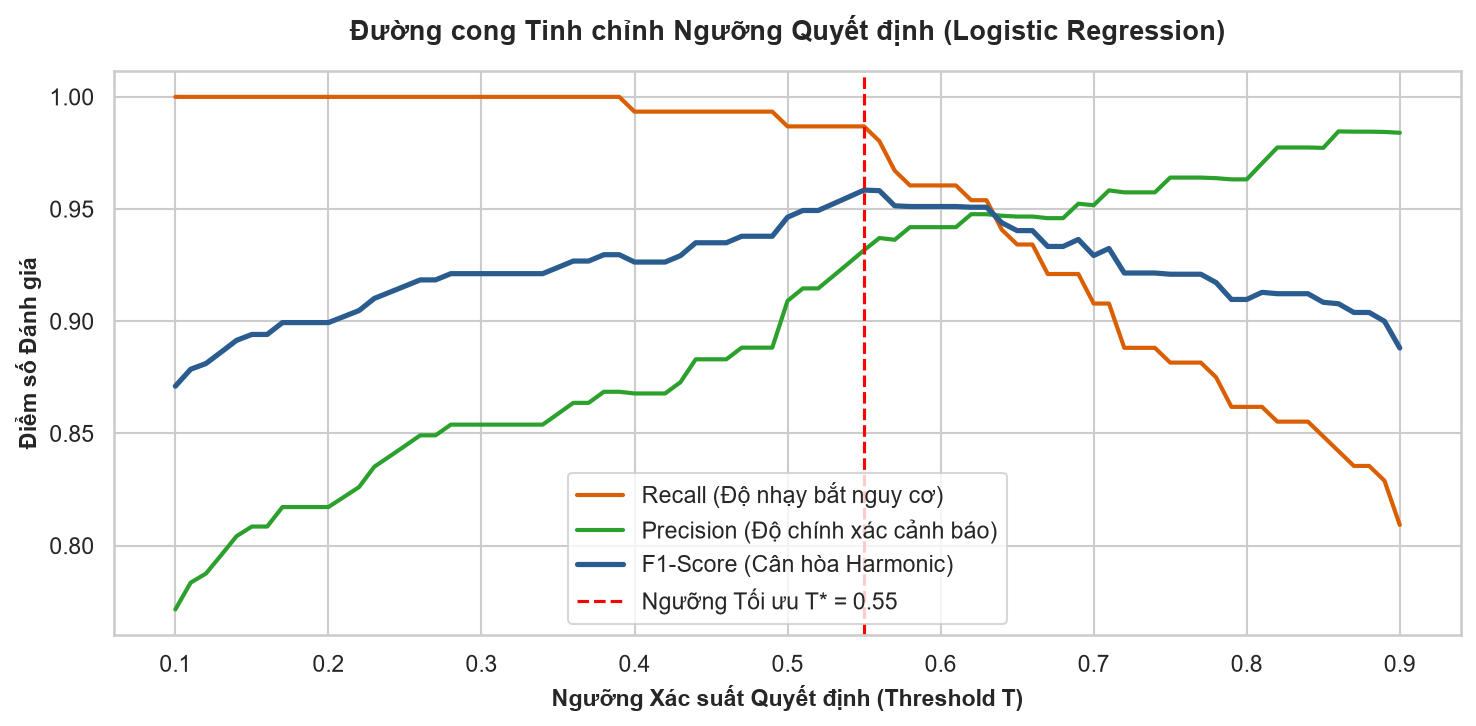

💾 Đã lưu Biểu đồ 8: d:\What-If Simulator\reports\figures\fig8_threshold_tuning_curves.png
🎯 Ngưỡng quyết định tối ưu: T* = 0.55
   - F1-Score:  0.9585
   - Recall:    98.68%
   - Precision: 93.17%


In [4]:
# CELL 4: Tinh chỉnh Ngưỡng Quyết định (Threshold Tuning) trên Dev Blackbox
# Để hỗ trợ GV/PH tối đa, ưu tiên Recall (không bỏ sót học sinh nguy cơ) trong khi vẫn giữ F1 > 0.90
y_dev_prob = best_pipeline.predict_proba(X_dev_bb)[:, 1]

thresholds = np.linspace(0.1, 0.9, 81)
f1_scores = []
recalls = []
precisions = []

for t in thresholds:
    preds = (y_dev_prob >= t).astype(int)
    recalls.append(recall_score(y_dev_bb, preds))
    precisions.append(precision_score(y_dev_bb, preds, zero_division=0))
    f1_scores.append(f1_score(y_dev_bb, preds))

# Tìm ngưỡng tối ưu F1
best_idx = np.argmax(f1_scores)
opt_threshold = thresholds[best_idx]
opt_f1 = f1_scores[best_idx]
opt_rec = recalls[best_idx]
opt_prec = precisions[best_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, recalls, label='Recall (Độ nhạy bắt nguy cơ)', color='#d95f02', lw=2)
plt.plot(thresholds, precisions, label='Precision (Độ chính xác cảnh báo)', color='#2ca02c', lw=2)
plt.plot(thresholds, f1_scores, label='F1-Score (Cân hòa Harmonic)', color='#2b5c8f', lw=2.5)
plt.axvline(opt_threshold, color='red', linestyle='--', label=f'Ngưỡng Tối ưu T* = {opt_threshold:.2f}')

plt.title(f"Đường cong Tinh chỉnh Ngưỡng Quyết định ({best_model_name})", fontsize=13, weight='bold', pad=15)
plt.xlabel("Ngưỡng Xác suất Quyết định (Threshold T)", fontsize=11, weight='bold')
plt.ylabel("Điểm số Đánh giá", fontsize=11, weight='bold')
plt.legend(loc='lower center', frameon=True)
plt.tight_layout()

fig8_path = os.path.join(FIGURES_DIR, 'fig8_threshold_tuning_curves.png')
plt.savefig(fig8_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 8: {fig8_path}")

print(f"🎯 Ngưỡng quyết định tối ưu: T* = {opt_threshold:.2f}")
print(f"   - F1-Score:  {opt_f1:.4f}")
print(f"   - Recall:    {opt_rec*100:.2f}%")
print(f"   - Precision: {opt_prec*100:.2f}%")

📊 BẢNG TỔNG KẾT PHÂN TÍCH LỖI TRÊN DEV EYEBALL (298 mẫu):
cohort_category
True Negative (TN)                225
True Positive (TP)                 64
False Positive (FP - Báo nhầm)      7
False Negative (FN - Bỏ sót)        2
Name: count, dtype: int64

💾 Đã lưu file nhật ký lỗi: d:\What-If Simulator\reports\error_logs\stage1_eyeball_errors.csv (9 bản ghi)


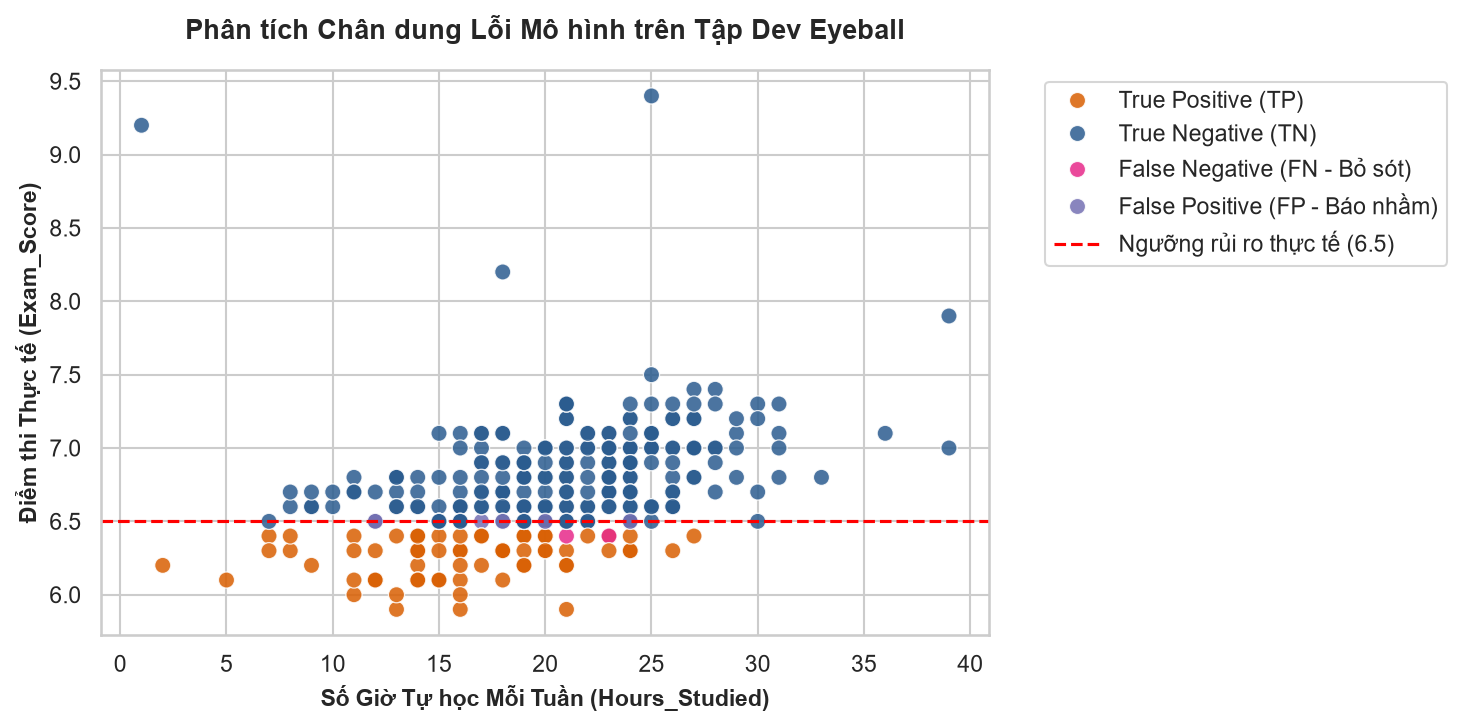

💾 Đã lưu Biểu đồ 9: d:\What-If Simulator\reports\figures\fig9_cohort_error_analysis.png


In [5]:
# CELL 5: Phân tích Lỗi Định tính & Định lượng trên Tập Dev Eyeball (Cohort Error Analysis)
y_eye_prob = best_pipeline.predict_proba(X_dev_eye)[:, 1]
y_eye_pred = (y_eye_prob >= opt_threshold).astype(int)

dev_eye_analysis = dev_eye_df.copy()
dev_eye_analysis['predicted_risk'] = y_eye_pred
dev_eye_analysis['risk_probability'] = y_eye_prob.round(4)

# Phân loại trạng thái dự đoán
conditions = [
    (dev_eye_analysis['at_risk'] == 1) & (dev_eye_analysis['predicted_risk'] == 1),
    (dev_eye_analysis['at_risk'] == 0) & (dev_eye_analysis['predicted_risk'] == 0),
    (dev_eye_analysis['at_risk'] == 1) & (dev_eye_analysis['predicted_risk'] == 0),
    (dev_eye_analysis['at_risk'] == 0) & (dev_eye_analysis['predicted_risk'] == 1)
]
choices = ['True Positive (TP)', 'True Negative (TN)', 'False Negative (FN - Bỏ sót)', 'False Positive (FP - Báo nhầm)']
dev_eye_analysis['cohort_category'] = np.select(conditions, choices, default='Other')

error_summary = dev_eye_analysis['cohort_category'].value_counts()
print("📊 BẢNG TỔNG KẾT PHÂN TÍCH LỖI TRÊN DEV EYEBALL (298 mẫu):")
print(error_summary)

# Xuất danh sách lỗi chi tiết ra CSV
errors_df = dev_eye_analysis[dev_eye_analysis['cohort_category'].isin(['False Negative (FN - Bỏ sót)', 'False Positive (FP - Báo nhầm)'])]
errors_csv_path = os.path.join(LOGS_DIR, 'stage1_eyeball_errors.csv')
errors_df.to_csv(errors_csv_path, index=False)
print(f"\n💾 Đã lưu file nhật ký lỗi: {errors_csv_path} ({len(errors_df)} bản ghi)")

# Vẽ biểu đồ chân dung các nhóm lỗi
plt.figure(figsize=(10, 5))
palette = {
    'True Positive (TP)': '#d95f02',
    'True Negative (TN)': '#2b5c8f',
    'False Negative (FN - Bỏ sót)': '#e7298a',
    'False Positive (FP - Báo nhầm)': '#7570b3'
}
sns.scatterplot(
    data=dev_eye_analysis, x='Hours_Studied', y='Exam_Score',
    hue='cohort_category', palette=palette, s=60, alpha=0.85
)
plt.axhline(6.5, color='red', linestyle='--', label='Ngưỡng rủi ro thực tế (6.5)')
plt.title("Phân tích Chân dung Lỗi Mô hình trên Tập Dev Eyeball", fontsize=13, weight='bold', pad=15)
plt.xlabel("Số Giờ Tự học Mỗi Tuần (Hours_Studied)", fontsize=11, weight='bold')
plt.ylabel("Điểm thi Thực tế (Exam_Score)", fontsize=11, weight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

fig9_path = os.path.join(FIGURES_DIR, 'fig9_cohort_error_analysis.png')
plt.savefig(fig9_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 9: {fig9_path}")

🏆 KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST ĐỘC LẬP (992 HỌC SINH):
   - ROC-AUC:   0.9974
   - Recall:    97.71%  (Bắt đúng 97.7% học sinh có nguy cơ)
   - Precision: 97.71%
   - F1-Score:  0.9771

Báo cáo Phân loại Chi tiết:
              precision    recall  f1-score   support

 An toàn (0)       0.99      0.99      0.99       774
 Nguy cơ (1)       0.98      0.98      0.98       218

    accuracy                           0.99       992
   macro avg       0.99      0.99      0.99       992
weighted avg       0.99      0.99      0.99       992



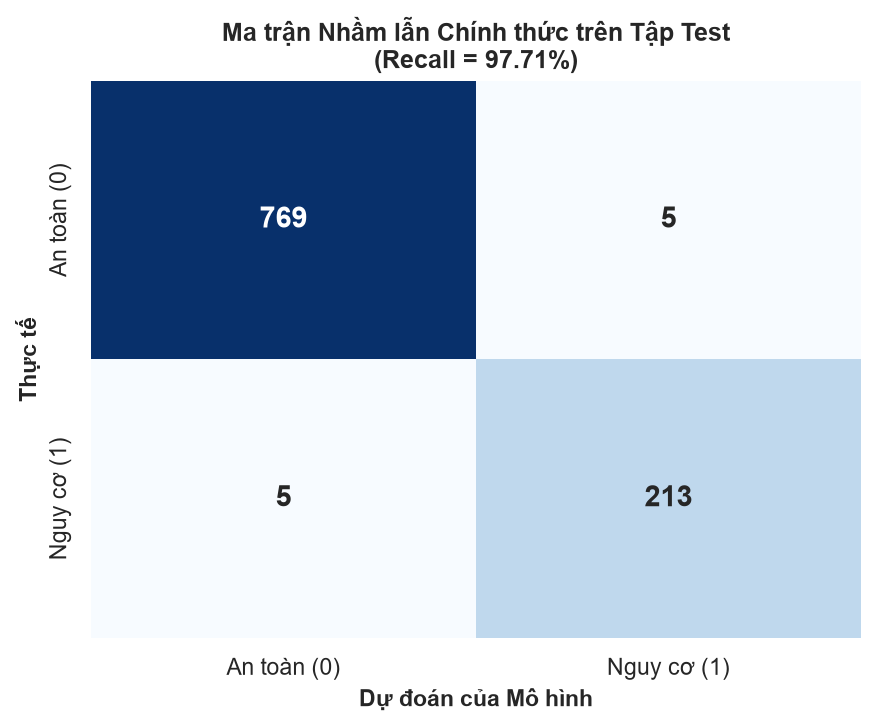

💾 Đã lưu Biểu đồ 10: d:\What-If Simulator\reports\figures\fig10_test_confusion_matrix.png

💾 Đã lưu pipeline thành công: d:\What-If Simulator\models\pipeline_stage1.pkl
💾 Đã cập nhật metadata: d:\What-If Simulator\models\model_metadata.json

🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 3 (NOTEBOOK 04)! 🏆


In [6]:
# CELL 6: Đánh giá Lần Cuối trên Tập Test (Hold-out Test 15%) & Xuất Pipeline Hoàn chỉnh
# MỞ NIÊM PHONG TẬP TEST
y_test_prob = best_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= opt_threshold).astype(int)

test_auc    = roc_auc_score(y_test, y_test_prob)
test_recall = recall_score(y_test, y_test_pred)
test_prec   = precision_score(y_test, y_test_pred)
test_f1     = f1_score(y_test, y_test_pred)

print("="*70)
print("🏆 KẾT QUẢ ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST ĐỘC LẬP (992 HỌC SINH):")
print(f"   - ROC-AUC:   {test_auc:.4f}")
print(f"   - Recall:    {test_recall*100:.2f}%  (Bắt đúng {test_recall*100:.1f}% học sinh có nguy cơ)")
print(f"   - Precision: {test_prec*100:.2f}%")
print(f"   - F1-Score:  {test_f1:.4f}")
print("="*70)
print("\nBáo cáo Phân loại Chi tiết:")
print(classification_report(y_test, y_test_pred, target_names=['An toàn (0)', 'Nguy cơ (1)']))

# Vẽ Ma trận nhầm lẫn Test
plt.figure(figsize=(6, 5))
cm_test = confusion_matrix(y_test, y_test_pred)
sns.heatmap(
    cm_test, annot=True, fmt='d', cmap='Blues', cbar=False,
    annot_kws={'size': 14, 'weight': 'bold'},
    xticklabels=['An toàn (0)', 'Nguy cơ (1)'],
    yticklabels=['An toàn (0)', 'Nguy cơ (1)']
)
plt.title(f"Ma trận Nhầm lẫn Chính thức trên Tập Test\n(Recall = {test_recall*100:.2f}%)", fontsize=12, weight='bold')
plt.xlabel("Dự đoán của Mô hình", fontsize=11, weight='bold')
plt.ylabel("Thực tế", fontsize=11, weight='bold')
plt.tight_layout()

fig10_path = os.path.join(FIGURES_DIR, 'fig10_test_confusion_matrix.png')
plt.savefig(fig10_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Đã lưu Biểu đồ 10: {fig10_path}")

# XUẤT PIPELINE VÀ METADATA
model_export_path = os.path.join(MODELS_DIR, 'pipeline_stage1.pkl')
joblib.dump(best_pipeline, model_export_path)
print(f"\n💾 Đã lưu pipeline thành công: {model_export_path}")

metadata = {
    "project": "He thong Ho tro Hoc tap Lop 12",
    "stage": 1,
    "task": "Binary Classification (at_risk < 6.5)",
    "target_column": "at_risk",
    "features_count": X_train.shape[1],
    "winning_algorithm": best_model_name,
    "optimal_threshold": float(opt_threshold),
    "dev_blackbox_metrics": {
        "roc_auc": float(df_results.iloc[0]['ROC-AUC']),
        "recall": float(opt_rec),
        "precision": float(opt_prec),
        "f1_score": float(opt_f1)
    },
    "test_metrics": {
        "roc_auc": float(test_auc),
        "recall": float(test_recall),
        "precision": float(test_prec),
        "f1_score": float(test_f1)
    }
}

metadata_path = os.path.join(MODELS_DIR, 'model_metadata.json')
# Cập nhật metadata json
if os.path.exists(metadata_path):
    with open(metadata_path, 'r', encoding='utf-8') as f:
        meta_all = json.load(f)
else:
    meta_all = {}

meta_all['stage1'] = metadata
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(meta_all, f, indent=2, ensure_ascii=False)
print(f"💾 Đã cập nhật metadata: {metadata_path}")

# Checkpoints kiểm định
assert test_recall >= 0.90, f"❌ Lỗi: Test Recall {test_recall:.4f} < 0.90!"
assert test_f1 >= 0.90, f"❌ Lỗi: Test F1 {test_f1:.4f} < 0.90!"
assert test_auc >= 0.95, f"❌ Lỗi: Test ROC-AUC {test_auc:.4f} < 0.95!"
print("\n🏆 CHÚC MỪNG BẠN ĐÃ HOÀN THÀNH 100% EPIC 3 (NOTEBOOK 04)! 🏆")